# 06. Query-based: RT-DETR

1. **Queries vs scene density:** are 300 queries enough for our frames?
2. **Sweep on fold 0** under the same compute budget as the CNN baseline: default, learning rate, denoising.
3. **Training dynamics:** held-out mAP against training hours, RT-DETR vs the YOLO baseline with the same budget.
4. **Small objects and dense scenes**, full cross-validation of the best experiment, submission.

In [1]:
import subprocess
import sys
from pathlib import Path

if Path("../src/core").exists():
    sys.path.insert(0, "../src")
else:
    repo = Path("/tmp/repo")  # outside /kaggle/working so it is not saved as output
    if not repo.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/mohinska/ai_hw2_MultipleObjectVideoDetection", str(repo)], check=True)
    sys.path.insert(0, str(repo / "src"))

In [2]:
!pip install -q ultralytics faster-coco-eval

In [3]:
import pandas as pd

from core.cv import compare, cv_table, environment, existing, run_cv
from core.data import assign_folds, find_data_root, load_pool, pool_targets
from core.evaluate import coco_evaluate
from core.fusion import fold_ensemble
from core.submission import write_submission
from core.yolo import make_yolo_fns, plot_budget_curves

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("../outputs")
WORK.mkdir(parents=True, exist_ok=True)
environment()

{'python': '3.13.16',
 'torch': '2.11.0+cu130',
 'torchvision': '0.26.0+cu130',
 'ultralytics': '8.4.208',
 'faster-coco-eval': '1.8.0',
 'pycocotools': '2.0.11',
 'scikit-learn': '1.6.1',
 'pandas': '2.3.3',
 'numpy': '2.1.3',
 'gpu': 'Tesla T4'}

In [4]:
DATA = find_data_root()
frames, gt = load_pool(DATA)
targets = pool_targets(gt)
frames["fold"] = frames["video"].map(assign_folds(frames))
frames["objects"] = frames["uid"].map(lambda u: len(targets[u][0]))
frames.groupby("fold").agg(clips=("video", "nunique"), frames=("uid", "size"))

,clips,frames
fold,,
0,19,6819
1,14,6767
2,15,6821
3,15,6640


## Queries vs scene density

In [5]:
frames["objects"].describe(percentiles=[0.5, 0.95, 0.99]).round(1).to_frame("objects per frame").T.assign(
    share_over_300=(frames["objects"] > 300).mean())

,count,mean,std,min,50%,95%,99%,max,share_over_300
objects per frame,27047.0,45.1,31.1,0.0,42.0,111.0,140.0,180.0,0.0


## How bipartite matching removes NMS
During training, the Hungarian algorithm matches each ground-truth object to exactly one query (cost =
class score + L1 + GIoU of the boxes); every other query is trained to predict "no object". Since one object
can only ever be claimed by one query, the decoder learns, through self-attention between queries, to suppress
its own duplicates, and no NMS is needed at inference.

This changes training dynamics: the assignment of queries to objects is unstable early on (a query matched
to one object in one step may get another in the next), so DETRs converge slower than CNN detectors with fixed
anchors or locations. RT-DETR shortens this with query selection from encoder features and denoising queries:
noised ground-truth boxes the decoder learns to reconstruct, which gives a stable learning signal while the
matching is still noisy.

In [6]:
BUDGET_HOURS = 1.5
BASE = dict(model="rtdetr-l.pt", imgsz=1280, epochs=100, batch=4, train_step=5, val_step=10,
            conf=0.001, iou=0.7, max_det=300, mask_ignore=True,
            train_args={"time": BUDGET_HOURS, "optimizer": "AdamW", "lr0": 1e-4, "weight_decay": 1e-4,
                        "cos_lr": True, "close_mosaic": 2})
EXPERIMENTS = {
    "rtdetr_default": BASE,
    "rtdetr_lr3e4": {**BASE, "train_args": {**BASE["train_args"], "lr0": 3e-4}},
    "rtdetr_no_denoising": {**BASE, "denoising": 0},
}
CNN = ["baseline"]


def config(name):
    return {**EXPERIMENTS[name], "name": name}

## Sweep on fold 0

In [7]:
for name in EXPERIMENTS:
    print(name)
    run_cv(frames, gt, config(name), *make_yolo_fns(config(name), WORK, targets), WORK, folds=[0])

rtdetr_default
fold 0: 4069 train frames, 6819 held-out frames (19 clips)
  mAP 0.0958  AP50 0.1772  AP_small 0.0199
rtdetr_lr3e4
fold 0: 4069 train frames, 6819 held-out frames (19 clips)
  mAP 0.1730  AP50 0.3175  AP_small 0.0238
rtdetr_no_denoising
fold 0: 4069 train frames, 6819 held-out frames (19 clips)
  mAP 0.1746  AP50 0.3373  AP_small 0.0327


### Fold-0 comparison and training dynamics
mAP against training hours on the same held-out frames. The baseline trains without masking ignored regions.

baseline: not run yet


,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_image
rtdetr_default,0.0958,0.1772,0.0931,0.0199,0.0844,0.1291,0.3958,198.3477
rtdetr_lr3e4,0.1730,0.3175,0.1696,0.0238,0.1679,0.2487,0.4335,197.5150
rtdetr_no_denoising,0.1746,0.3373,0.1637,0.0327,0.1395,0.2643,0.4284,197.6092


baseline: no results.csv for fold 0


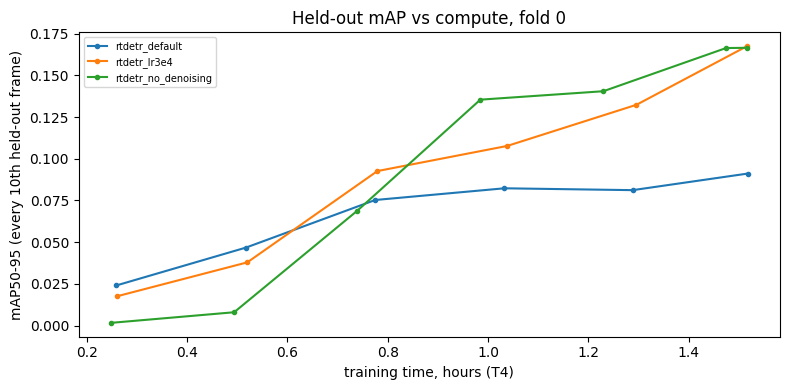

In [8]:
sweep = compare([*EXPERIMENTS, *CNN], WORK, fold=0)
display(sweep.round(4))
plot_budget_curves([*EXPERIMENTS, *CNN], 0, WORK);

### Small objects and dense scenes (fold 0)
mAP on frames with more than 100 objects vs the rest, next to AP_small from the table above.

In [9]:
held0 = frames[frames["fold"] == 0]
subsets = {"dense (>100 objects)": held0[held0["objects"] > 100], "other": held0[held0["objects"] <= 100]}
rows = {}
for name in [*EXPERIMENTS, *CNN]:
    f = existing(f"oof_{name}_fold0.parquet", WORK)
    if f is not None:
        dets = pd.read_parquet(f)
        rows[name] = {s: coco_evaluate(dets, fr, gt)["mAP"] for s, fr in subsets.items()}
pd.DataFrame(rows).T.assign(frames_dense=len(subsets["dense (>100 objects)"])).round(4)

,dense (>100 objects),other,frames_dense
rtdetr_default,0.2360,0.0867,187
rtdetr_lr3e4,0.2865,0.1652,187
rtdetr_no_denoising,0.2651,0.1695,187


## Full cross-validation of the best experiment
Chosen on fold 0, so its fold-0 score is slightly optimistic.

In [10]:
BEST = sweep.loc[sweep.index.isin(EXPERIMENTS), "mAP"].idxmax()
print("best on fold 0:", BEST)
_, predict_fn = make_yolo_fns(config(BEST), WORK, targets)
result = run_cv(frames, gt, config(BEST), *make_yolo_fns(config(BEST), WORK, targets), WORK)

best on fold 0: rtdetr_no_denoising
fold 0: 4069 train frames, 6819 held-out frames (19 clips)
  mAP 0.1746  AP50 0.3373  AP_small 0.0327
fold 1: 4077 train frames, 6767 held-out frames (14 clips)
  mAP 0.1689  AP50 0.3213  AP_small 0.0430
fold 2: 4067 train frames, 6821 held-out frames (15 clips)
  mAP 0.0005  AP50 0.0039  AP_small 0.0005
fold 3: 4104 train frames, 6640 held-out frames (15 clips)
  mAP 0.1612  AP50 0.2927  AP_small 0.0522


In [11]:
display(compare([BEST, *CNN], WORK).round(4))  # out-of-fold over all frames
cv_table(result).round(4)

baseline: not run yet


,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_image
rtdetr_no_denoising,0.1124,0.2171,0.1061,0.0266,0.1028,0.1833,0.2824,196.1109


,mAP,AP50,AP_small,AP_medium,AP_large,ms_per_image
fold 0,0.1746,0.3373,0.0327,0.1395,0.2643,197.6092
fold 1,0.1689,0.3213,0.0430,0.1713,0.3040,197.5056
fold 2,0.0005,0.0039,0.0005,0.0007,0.0023,197.3869
fold 3,0.1612,0.2927,0.0522,0.1357,0.2987,191.9419
mean,0.1263,0.2388,0.0321,0.1118,0.2173,196.1109
std,0.0841,0.1577,0.0225,0.0758,0.1444,2.7808
OOF,0.1124,0.2171,0.0266,0.1028,0.1833,196.1109


In [12]:
test = pd.read_csv(DATA / "test_images.csv")
test_dets = fold_ensemble(BEST, predict_fn, [str(DATA / f) for f in test["file_name"]], WORK)
write_submission(test_dets, test, WORK / f"submission_{BEST}.csv").head()

fold 0 model: 1143300 boxes
fold 1 model: 1143300 boxes
fold 2 model: 1143300 boxes
fold 3 model: 1143300 boxes


,image_id,PredictionString
0,clip_001_0000001,0 0.7102 1658.9 786.4 60.9 151.9 0 0.6461 777....
1,clip_001_0000002,0 0.6905 1723.1 791.5 55.4 154.3 0 0.6712 775....
2,clip_001_0000003,0 0.6071 615.8 932.5 65.4 150.1 0 0.5739 1669....
3,clip_001_0000004,0 0.6739 1726.8 803.5 58.0 155.1 0 0.6732 1670...
4,clip_001_0000005,0 0.6462 1666.4 803.5 57.5 154.7 0 0.6222 674....
